# 03 · Models and evaluation (Parts B and C)

**Colab: Runtime → Change runtime type → T4 GPU, then Runtime → Run all** (about 55 minutes; finished runs are saved to Google Drive, so after a disconnect just Run all again).

| Part | What | Files in `results/` |
|---|---|---|
| B · Models | colour/brightness baseline; U-Net from scratch vs. ImageNet-pretrained, 3 seeds each | `B1_*`, `B2_*` |
| C · Evaluation | test set **once**: table, bootstrap interval, worst cases, Grad-CAM, uncertainty | `C1_*` … `C5_*` |

One change at a time: both U-Nets have the same architecture, split, budget, seeds and
settings; only the encoder's starting weights differ (random vs. ImageNet).

In [1]:
# ============ SETTINGS ============
EPOCHS = 30          # per training run (about 45-75 min in total on a T4)
SEEDS = [0, 1, 2]    # 3 seeds per model
QUICK = False        # True = tiny test run (1 epoch, few images) to check the code on a laptop
# ==================================

## Setup

In [2]:
import os, sys, json, time
# On Colab: download our code from GitHub first (on a laptop it is already there).
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
# If started inside chandana/ or dinesh/, go up to the project folder, so data/ and src/ are found.
if os.path.basename(os.getcwd()) in ("chandana", "dinesh"):
    os.chdir("..")
# Data not there yet: download Kvasir-SEG (46 MB) and the authors' split lists.
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py
# Split not made yet: fingerprints, duplicate check, train/val/test lists.
if not os.path.exists("splits/train.txt"):
    !python scripts/make_split.py
# Let Python import our own modules from src/.
sys.path.insert(0, "src")

import numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from pathlib import Path
from data import load_resized, read_split
from metrics import mean_scores
import baseline
from train import train_model, predict_probs, to_tensor, normalise

# Use the GPU if there is one (Colab T4), otherwise the CPU.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(no GPU: training will be very slow)")
# Every table and figure is saved in results/.
R = Path("results"); R.mkdir(exist_ok=True)

# Load all images and masks at 256 x 256: X = images, M = masks, NAMES = file names.
X, M, NAMES = {}, {}, {}
for s in ("train", "val", "test"):
    NAMES[s] = read_split(s)
    if QUICK and s == "train":
        NAMES[s] = NAMES[s][:48]
    pairs = [load_resized(n, 256) for n in NAMES[s]]
    X[s] = np.stack([p[0] for p in pairs]); M[s] = np.stack([p[1] for p in pairs])
    print(s, X[s].shape)
if QUICK:
    EPOCHS, SEEDS = 1, [0]

Cloning into 'kvasir-seg-polyp-segmentation'...
remote: Enumerating objects: 127, done.
remote: Counting objects: 100% (127/127), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 127 (delta 48), reused 100 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (127/127), 11.54 MiB | 31.17 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/kvasir-seg-polyp-segmentation
Certificate problem on the Simula server; adding its missing certificate ...
Unzipping ...
Done: 1000 images, 1000 masks in data/Kvasir-SEG/
device: cuda Tesla T4
train (779, 256, 256, 3)
val (100, 256, 256, 3)
test (120, 256, 256, 3)


---
# Part B · Models
## B1 · Classical baseline: brightness threshold (no learning)
`src/baseline.py` explains each step. Polyps are brighter than the bowel wall (checked on
validation; our first idea, redness, scored only Dice 0.02). The clean-up size is chosen
on **validation** only.

radius  3: validation Dice 0.380
radius  7: validation Dice 0.387
radius 11: validation Dice 0.390
radius 15: validation Dice 0.388
chosen radius: 11


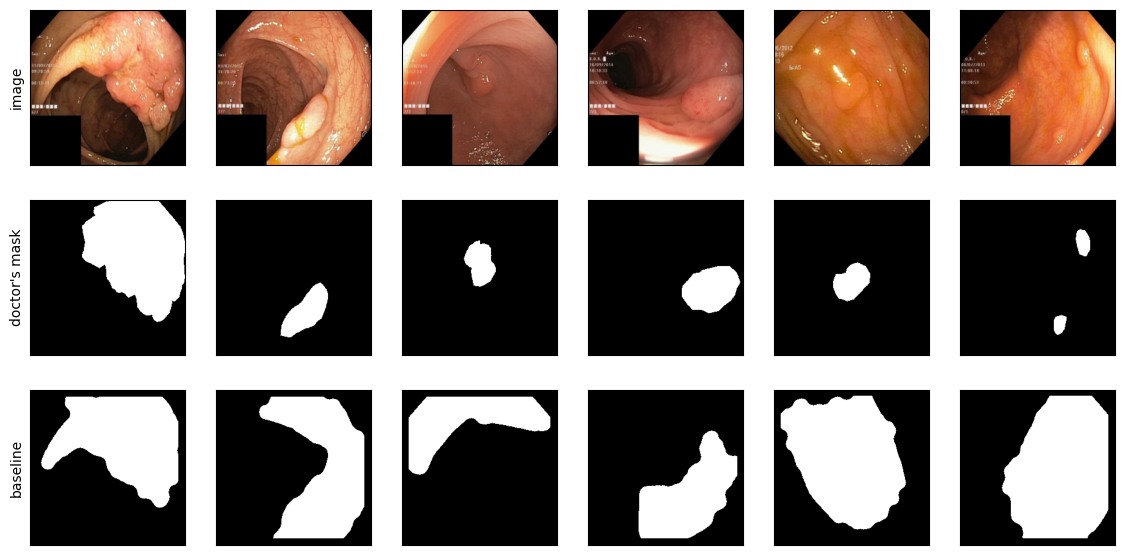

In [3]:
radius_scores = {}
# B1: try 4 clean-up sizes on the VALIDATION images and keep the best (never on test).
for r in (3, 7, 11, 15):
    preds = [baseline.predict(x, r) for x in X["val"]]
    radius_scores[r] = mean_scores(preds, M["val"])["dice"]
    print(f"radius {r:2d}: validation Dice {radius_scores[r]:.3f}")
# The radius with the highest validation Dice (result: 11).
RADIUS = max(radius_scores, key=radius_scores.get)
print("chosen radius:", RADIUS)

# Show 6 validation images: photo, doctor's mask, baseline guess.
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for k, i in enumerate(range(6)):
    p = baseline.predict(X["val"][i], RADIUS)
    axes[0, k].imshow(X["val"][i]); axes[1, k].imshow(M["val"][i], cmap="gray"); axes[2, k].imshow(p, cmap="gray")
for a, t in zip(axes[:, 0], ["image", "doctor's mask", "baseline"]):
    a.set_ylabel(t)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
fig.savefig(R / "B1_baseline_examples.png", dpi=120, bbox_inches="tight"); plt.show()

## B2 · U-Net: from scratch vs. ImageNet-pretrained, 3 seeds each
Each run keeps the epoch with the best **validation** Dice. The test set is not touched here.

Mounted at /content/drive
=== U-Net scratch, seed 0: already trained, loading scratch_seed0_epochs30.pt ===
=== U-Net scratch, seed 1: already trained, loading scratch_seed1_epochs30.pt ===
=== U-Net scratch, seed 2: already trained, loading scratch_seed2_epochs30.pt ===
=== U-Net pretrained, seed 0: already trained, loading pretrained_seed0_epochs30.pt ===
=== U-Net pretrained, seed 1: already trained, loading pretrained_seed1_epochs30.pt ===
=== U-Net pretrained, seed 2: already trained, loading pretrained_seed2_epochs30.pt ===

mean time per epoch: 18.3 s on cuda


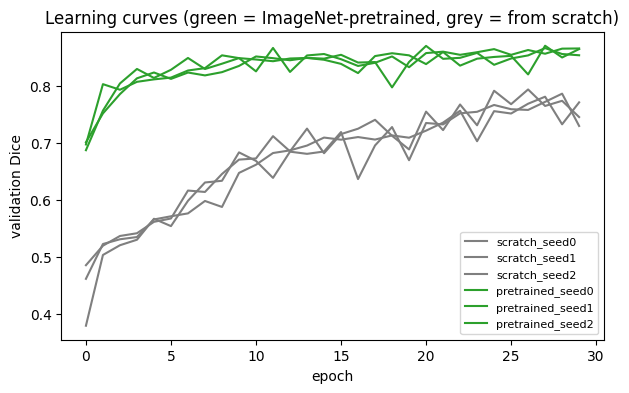

In [4]:
# Every finished run is saved, so a disconnect does not lose it: on Colab to Google Drive
# (a window asks for permission once), on a laptop to checkpoints/. Running this cell again
# loads the finished runs and only trains the missing ones.
from unet import UNet
if "google.colab" in sys.modules and not QUICK:
    from google.colab import drive
    # Google Drive keeps the trained models between Colab sessions.
    drive.mount("/content/drive")
    SAVE = Path("/content/drive/MyDrive/kvasir_seg_runs")
else:
    SAVE = Path("checkpoints")
SAVE.mkdir(parents=True, exist_ok=True)

models, histories = {}, {}
# B2: train 2 kinds x 3 seeds = 6 U-Nets. The ONLY difference: pretrained or not.
for pretrained in (False, True):
    name = "pretrained" if pretrained else "scratch"
    for seed in SEEDS:
        weights_file = SAVE / f"{name}_seed{seed}_epochs{EPOCHS}.pt"
        history_file = SAVE / f"{name}_seed{seed}_epochs{EPOCHS}.json"
        # Already trained in an earlier session: just load it (resume after a disconnect).
        if weights_file.exists() and history_file.exists() and not QUICK:
            print(f"=== U-Net {name}, seed {seed}: already trained, loading {weights_file.name} ===")
            model = UNet(pretrained=False)          # the saved weights replace the start weights
            model.load_state_dict(torch.load(weights_file, map_location="cpu"))
            hist = json.loads(history_file.read_text())
        else:
            print(f"\n=== U-Net {name}, seed {seed} ===")
            # Not trained yet: train for 30 epochs and keep the best validation epoch.
            model, hist = train_model(pretrained, seed, X["train"], M["train"], X["val"], M["val"],
                                      device, epochs=EPOCHS)
            # Save the weights at once, so a Colab disconnect cannot lose them.
            torch.save(model.state_dict(), weights_file)
            history_file.write_text(json.dumps(hist))
        models[(name, seed)] = model.cpu()
        histories[f"{name}_seed{seed}"] = hist
(R / "B2_histories.json").write_text(json.dumps(histories, indent=1))
# Mean seconds per epoch (18.3 s on a T4).
sec = np.mean([h["seconds"] for hs in histories.values() for h in hs])
print(f"\nmean time per epoch: {sec:.1f} s on {device}")

# Learning curves: validation Dice after every epoch, one line per run.
fig, ax = plt.subplots(figsize=(7, 4))
for key, hist in histories.items():
    ax.plot([h["val_dice"] for h in hist], color="tab:green" if "pretrained" in key else "tab:gray",
            label=key)
ax.set_xlabel("epoch"); ax.set_ylabel("validation Dice"); ax.legend(fontsize=8)
ax.set_title("Learning curves (green = ImageNet-pretrained, grey = from scratch)")
fig.savefig(R / "B2_learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()

---
# Part C · Evaluation: the test set, used **once**
## C1 · The results table

| Setting | Dice | IoU | Precision | Recall |
|---|---|---|---|---|
| floor: always polyp | 0.243 | 0.153 | 0.153 | 1.000 |
| floor: always background | 0.000 | 0.000 | 0.000 | 0.000 |
| brightness threshold (radius 11) | 0.323 | 0.223 | 0.304 | 0.598 |
| U-Net scratch (3 seeds) | 0.756 ± 0.009 | 0.661 ± 0.014 | 0.790 ± 0.025 | 0.807 ± 0.021 |
| U-Net pretrained (3 seeds) | 0.862 ± 0.007 | 0.788 ± 0.011 | 0.864 ± 0.029 | 0.912 ± 0.016 |


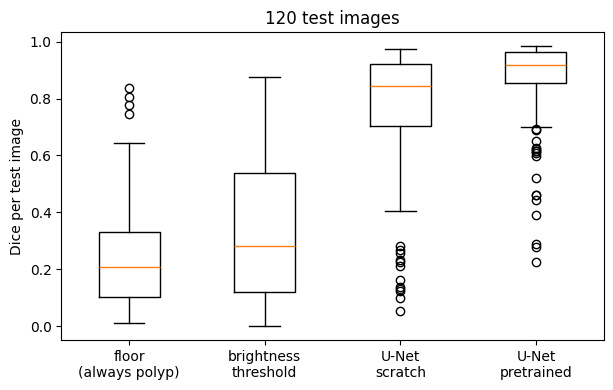

In [5]:
# C1: the TEST set, used once, here at the end. Y = the doctor's masks.
Y = M["test"]
rows, per_image = [], {}
# floor
# Floor 'always polyp': every pixel called polyp (Dice 0.243).
fl = mean_scores([np.ones_like(m) for m in Y], Y)
rows.append(("floor: always polyp", fl, None)); per_image["floor"] = fl["dice_per_image"]
rows.append(("floor: always background", mean_scores([np.zeros_like(m) for m in Y], Y), None))
# classical baseline
# Brightness baseline with the radius chosen on validation.
bl = mean_scores([baseline.predict(x, RADIUS) for x in X["test"]], Y)
rows.append((f"brightness threshold (radius {RADIUS})", bl, None)); per_image["baseline"] = bl["dice_per_image"]
# U-Nets: one score per seed, then mean ± std over seeds
probs = {}
for name in ("scratch", "pretrained"):
    seed_scores = []
    for seed in SEEDS:
        model = models[(name, seed)].to(device)
        # Polyp probability for every test pixel; > 0.5 = polyp.
        probs[(name, seed)] = predict_probs(model, X["test"], device)
        models[(name, seed)] = model.cpu()
        seed_scores.append(mean_scores(probs[(name, seed)] > 0.5, Y))
    # Mean over the 3 seeds...
    mean = {k: float(np.mean([s[k] for s in seed_scores])) for k in ("dice", "iou", "precision", "recall")}
    # ... and the spread (standard deviation, ddof=1) over the 3 seeds.
    std = {k: float(np.std([s[k] for s in seed_scores], ddof=1)) if len(SEEDS) > 1 else 0.0 for k in mean}
    rows.append((f"U-Net {name} ({len(SEEDS)} seeds)", mean, std))
    # Dice per test image (mean of the 3 seeds) for the paired tests in src/stats.py.
    per_image[name] = list(np.mean([s["dice_per_image"] for s in seed_scores], axis=0))

lines = ["| Setting | Dice | IoU | Precision | Recall |", "|---|---|---|---|---|"]
for label, m, s in rows:
    f = (lambda k: f"{m[k]:.3f} ± {s[k]:.3f}") if s else (lambda k: f"{m[k]:.3f}")
    lines.append(f"| {label} | {f('dice')} | {f('iou')} | {f('precision')} | {f('recall')} |")
table = "\n".join(lines)
(R / "C1_results.md").write_text(table, encoding="utf-8"); print(table)
# Save Dice per image: src/stats.py and dinesh/hard_images.ipynb read this file.
json.dump({k: [float(v) for v in vals] for k, vals in per_image.items()}, open(R / "C1_dice_per_image.json", "w"))

fig, ax = plt.subplots(figsize=(7, 4))
# Box plot: the spread of Dice over the 120 test images for each step of the ladder.
ax.boxplot([per_image[k] for k in ("floor", "baseline", "scratch", "pretrained")],
           tick_labels=["floor\n(always polyp)", "brightness\nthreshold", "U-Net\nscratch", "U-Net\npretrained"])
ax.set_ylabel("Dice per test image"); ax.set_title("120 test images")
fig.savefig(R / "C1_boxplot.png", dpi=150, bbox_inches="tight"); plt.show()

## C2 · How sure are we? Bootstrap interval, and groups of test images
Bootstrap: draw the 120 test images again 2,000 times with replacement and look at the spread
of the mean Dice. Groups: small polyps (< 5 % of the image) and the 23 images from the
later batch (not seen in training, see notebook 02).

In [6]:
# C2: bootstrap interval and subgroups (small polyps, later batch).
rng = np.random.default_rng(0)
lines = ["| Setting | Dice | 95 % bootstrap interval | small polyps (< 5 %) | later batch (23) | rest |", "|---|---|---|---|---|---|"]
# Small polyp = under 5 % of the image.
small = np.array([m.mean() < 0.05 for m in Y])
# File-name prefixes of the later batch (images added in a later dataset version).
LATER = ("cjyz", "cjz1", "ck23", "ck2b", "ck2d")
later = np.array([n[:4] in LATER for n in NAMES["test"]])
for key, label in [("baseline", "brightness threshold"), ("scratch", "U-Net scratch"), ("pretrained", "U-Net pretrained")]:
    d = np.array(per_image[key])
    # Bootstrap: draw 120 test images WITH replacement, 2,000 times, and take the mean Dice each time.
    boot = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(2000)]
    # The middle 95 % of the 2,000 means = the 95 % interval.
    lo, hi = np.percentile(boot, [2.5, 97.5])
    lines.append(f"| {label} | {d.mean():.3f} | {lo:.3f} to {hi:.3f} | {d[small].mean():.3f} (n={small.sum()}) "
                 f"| {d[later].mean():.3f} | {d[~later].mean():.3f} (n={(~later).sum()}) |")
text = "\n".join(lines); (R / "C2_intervals_and_groups.md").write_text(text, encoding="utf-8"); print(text)

| Setting | Dice | 95 % bootstrap interval | small polyps (< 5 %) | later batch (23) | rest |
|---|---|---|---|---|---|
| brightness threshold | 0.323 | 0.282 to 0.370 | 0.146 (n=29) | 0.304 | 0.328 (n=97) |
| U-Net scratch | 0.756 | 0.712 to 0.795 | 0.706 (n=29) | 0.754 | 0.756 (n=97) |
| U-Net pretrained | 0.862 | 0.832 to 0.888 | 0.843 (n=29) | 0.809 | 0.874 (n=97) |


## C3 · The worst cases: the 8 test images where the pretrained U-Net does worst

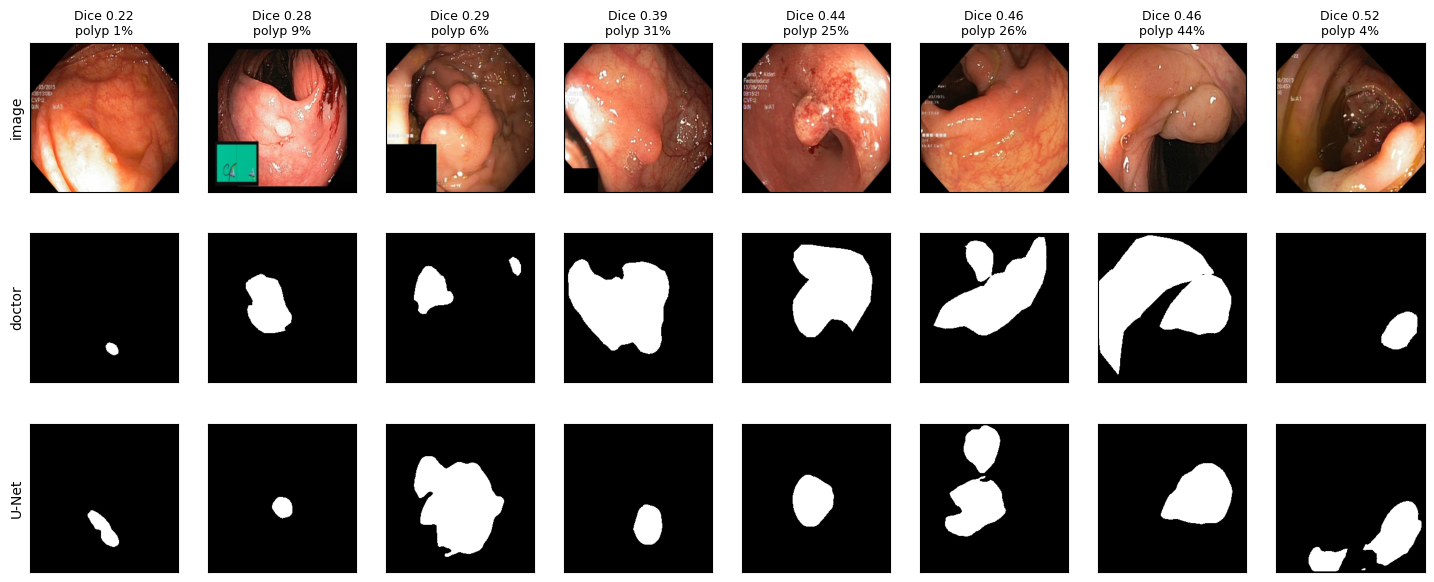

worst images: ['cju0tl3uz8blh0993wxvn7ly3', 'ck2bxqz3evvg20794iiyv5v2m', 'cju87kbcen2av0987usezo8kn', 'ck2bxw18mmz1k0725litqq2mc', 'cju7dubap2g0w0801fgl42mg9', 'cju16whaj0e7n0855q7b6cjkm', 'ck2bxiswtxuw80838qkisqjwz', 'cju0sxqiclckk08551ycbwhno']


In [7]:
# C3: ensemble = mean probability of the 3 seeds.
ens = np.mean([probs[("pretrained", s)] for s in SEEDS], axis=0)       # mean of the 3 seeds
# The 8 test images with the lowest Dice.
d = np.array(per_image["pretrained"]); worst = np.argsort(d)[:8]
fig, axes = plt.subplots(3, 8, figsize=(18, 7))
for k, i in enumerate(worst):
    axes[0, k].imshow(X["test"][i]); axes[0, k].set_title(f"Dice {d[i]:.2f}\npolyp {Y[i].mean():.0%}", fontsize=9)
    axes[1, k].imshow(Y[i], cmap="gray"); axes[2, k].imshow(ens[i] > 0.5, cmap="gray")
for a, t in zip(axes[:, 0], ["image", "doctor", "U-Net"]):
    a.set_ylabel(t)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
fig.savefig(R / "C3_worst_cases.png", dpi=120, bbox_inches="tight"); plt.show()
print("worst images:", [NAMES["test"][i] for i in worst])

## C4 · What does it look at, and where is it unsure?
- **Grad-CAM** (pretrained, seed 0): which parts of the deepest encoder layer push the
  predicted polyp pixels up. Red = strong.
- **Uncertainty**: the standard deviation of the 3 seed models' probability per pixel.
  Bright = the 3 models disagree.
Neither proves the model is right; they show where to look.

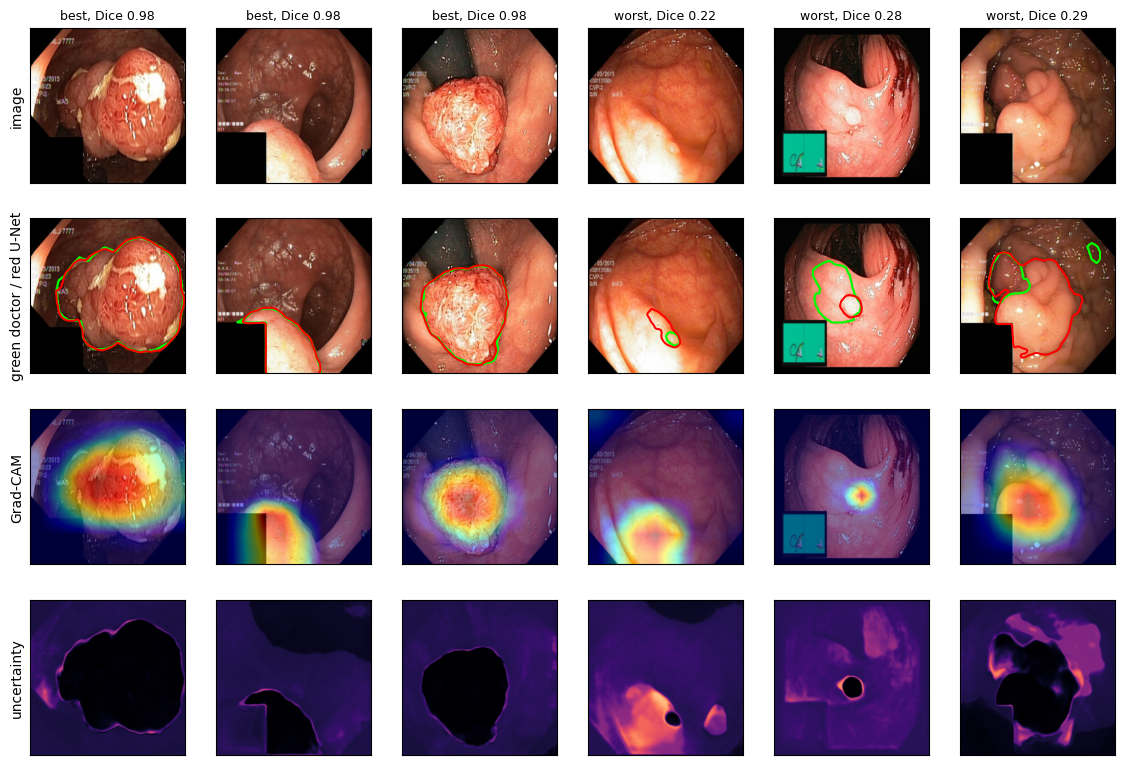

In [8]:
# C4: Grad-CAM = which areas of layer4 (8 x 8) raised the 'polyp' output.
def gradcam(model, x):
    acts = {}
    # A hook saves layer4's output (the activations) during the forward pass.
    hook = model.layer4.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    out = model(x); hook.remove()
    # What we explain: the sum of logits of the pixels called polyp.
    target = (out * (out > 0).float()).sum()            # the pixels it calls polyp
    # Gradients: how much each layer4 feature changes that target.
    g = torch.autograd.grad(target, acts["a"])[0]
    # Weight each feature map by its mean gradient, add up, keep only positive values (ReLU).
    cam = F.relu((g.mean((2, 3), keepdim=True) * acts["a"]).sum(1, keepdim=True))
    # Enlarge 8 x 8 to 256 x 256 (that is why the maps look like blobs).
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear")[:, 0]
    return (cam / (cam.amax((1, 2), keepdim=True) + 1e-8)).detach().cpu().numpy()

model = models[("pretrained", SEEDS[0])].to(device).eval()
# 3 best and 3 worst test images.
show = list(np.argsort(-d)[:3]) + list(worst[:3])            # 3 best, 3 worst
cams = gradcam(model, normalise(to_tensor(X["test"][show]).to(device)))
# Uncertainty = how much the 3 seeds disagree, per pixel.
spread = np.std([probs[("pretrained", s)] for s in SEEDS], axis=0)
fig, axes = plt.subplots(4, 6, figsize=(14, 9.5))
for k, i in enumerate(show):
    axes[0, k].imshow(X["test"][i]); axes[0, k].set_title(("best" if k < 3 else "worst") + f", Dice {d[i]:.2f}", fontsize=9)
    axes[1, k].imshow(X["test"][i]); axes[1, k].contour(Y[i], [0.5], colors="lime"); axes[1, k].contour(ens[i], [0.5], colors="red")
    axes[2, k].imshow(X["test"][i]); axes[2, k].imshow(cams[k], cmap="jet", alpha=0.45)
    axes[3, k].imshow(spread[i], cmap="magma", vmin=0, vmax=0.5)
for a, t in zip(axes[:, 0], ["image", "green doctor / red U-Net", "Grad-CAM", "uncertainty"]):
    a.set_ylabel(t)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
fig.savefig(R / "C4_gradcam_uncertainty.png", dpi=120, bbox_inches="tight"); plt.show()
models[("pretrained", SEEDS[0])] = model.cpu()

## C5 · Summary and files

In [9]:
# C5: a short summary, then all results zipped for download.
summary = f"""Kvasir-SEG, {len(Y)} test images (the authors' test list), used once.
{table}

Time per epoch: {sec:.1f} s on {device}; {EPOCHS} epochs; seeds {SEEDS}; best epoch by validation Dice.
Classical baseline: brightness (Lab L) + Otsu + clean-up radius {RADIUS} (chosen on validation).
"""
(R / "C5_summary.md").write_text(summary, encoding="utf-8"); print(summary)
import zipfile
with zipfile.ZipFile("results.zip", "w") as z:
    for f in sorted(R.iterdir()):
        z.write(f)
try:
    from google.colab import files; files.download("results.zip")
except ImportError:
    print("results.zip written")

Kvasir-SEG, 120 test images (the authors' test list), used once.
| Setting | Dice | IoU | Precision | Recall |
|---|---|---|---|---|
| floor: always polyp | 0.243 | 0.153 | 0.153 | 1.000 |
| floor: always background | 0.000 | 0.000 | 0.000 | 0.000 |
| brightness threshold (radius 11) | 0.323 | 0.223 | 0.304 | 0.598 |
| U-Net scratch (3 seeds) | 0.756 ± 0.009 | 0.661 ± 0.014 | 0.790 ± 0.025 | 0.807 ± 0.021 |
| U-Net pretrained (3 seeds) | 0.862 ± 0.007 | 0.788 ± 0.011 | 0.864 ± 0.029 | 0.912 ± 0.016 |

Time per epoch: 18.3 s on cuda; 30 epochs; seeds [0, 1, 2]; best epoch by validation Dice.
Classical baseline: brightness (Lab L) + Otsu + clean-up radius 11 (chosen on validation).



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>